<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/hough_sin_cos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

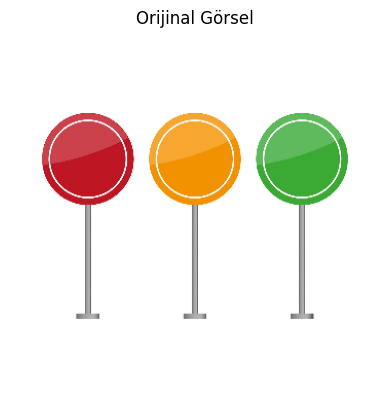

In [3]:
orijinal = cv2.imread("image10.jpeg")

h0, w0 = orijinal.shape[:2]

oran = min(1, 360 / max(h0, w0))

resim = cv2.resize(
    orijinal, None, fx=oran, fy=oran
)

plt.imshow(cv2.cvtColor(resim, cv2.COLOR_BGR2RGB))
plt.title("Orijinal Görsel")
plt.axis("off")
plt.show()

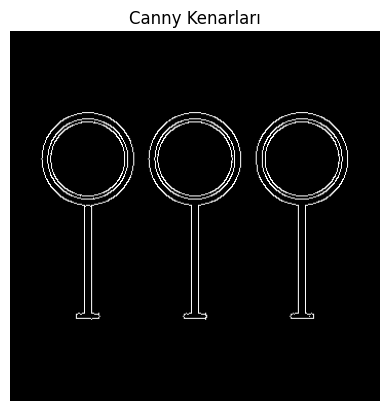

In [4]:
gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)

bulanik = cv2.GaussianBlur(gri, (5, 5), 1.2)

kenarlar = cv2.Canny(bulanik, 50, 130)

plt.imshow(kenarlar, cmap="gray")
plt.title("Canny Kenarları")
plt.axis("off")
plt.show()

In [5]:
acilar = np.deg2rad(np.arange(0, 360, 10))

sin_tablosu = np.sin(acilar)
cos_tablosu = np.cos(acilar)

print("Açı sayısı:", len(acilar))
print("Sin tablosu:", sin_tablosu[:5])
print("Cos tablosu:", cos_tablosu[:5])

Açı sayısı: 36
Sin tablosu: [0.         0.17364818 0.34202014 0.5        0.64278761]
Cos tablosu: [1.         0.98480775 0.93969262 0.8660254  0.76604444]


In [6]:
yukseklik, genislik = kenarlar.shape

min_r = max(8, int(min(yukseklik, genislik) * 0.05))
max_r = int(min(yukseklik, genislik) * 0.25)

yaricaplar = np.arange(min_r, max_r + 1, 2)

oylama = np.zeros(
    (len(yaricaplar), yukseklik, genislik),
    dtype=np.int32
)

print("Oylama matrisi boyutu:", oylama.shape)
print("Yarıçap sayısı:", len(yaricaplar))

Oylama matrisi boyutu: (37, 360, 360)
Yarıçap sayısı: 37


In [8]:
ys, xs = np.where(kenarlar > 0)

for i, r in enumerate(yaricaplar):

    for t in range(len(acilar)):

        a = np.rint(
            xs - r * cos_tablosu[t]
        ).astype(int)

        b = np.rint(
            ys - r * sin_tablosu[t]
        ).astype(int)

        gecerli = (
            (a >= 0) & (a < genislik) &
            (b >= 0) & (b < yukseklik)
        )

        np.add.at(
            oylama[i],
            (b[gecerli], a[gecerli]),
            1
        )

print("En yüksek oy:", oylama.max())

En yüksek oy: 66


Örnek kenar noktası: 70 79
Denenen yarıçap: 18
Açı: 0 Merkez: (52, 79)
Açı: 90 Merkez: (70, 61)
Açı: 180 Merkez: (88, 79)
Açı: 270 Merkez: (70, 97)


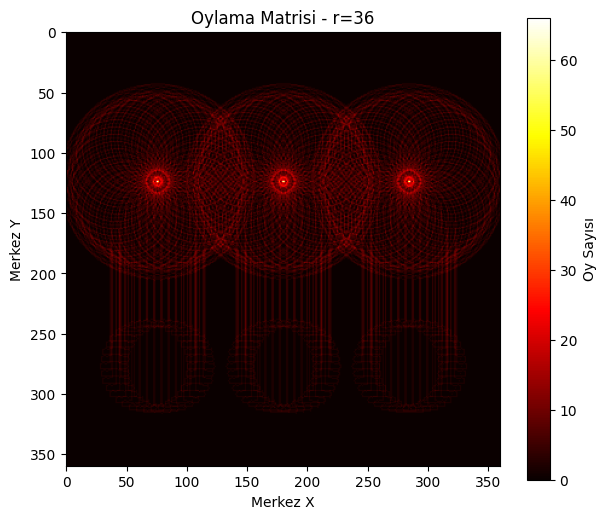

In [9]:
if len(xs) > 0:
    x = int(xs[0])
    y = int(ys[0])
    r = int(yaricaplar[0])

    print("Örnek kenar noktası:", x, y)
    print("Denenen yarıçap:", r)

    for t in [0, 9, 18, 27]:
        a = round(x - r * cos_tablosu[t])
        b = round(y - r * sin_tablosu[t])

        print(
            "Açı:", t * 10,
            "Merkez:", (a, b)
        )

r_indeks, _, _ = np.unravel_index(
    np.argmax(oylama), oylama.shape
)

plt.figure(figsize=(7, 6))

plt.imshow(oylama[r_indeks], cmap="hot")
plt.title(f"Oylama Matrisi - r={yaricaplar[r_indeks]}")
plt.xlabel("Merkez X")
plt.ylabel("Merkez Y")
plt.colorbar(label="Oy Sayısı")

plt.savefig("oylama_kesiti.png", dpi=200)
plt.show()

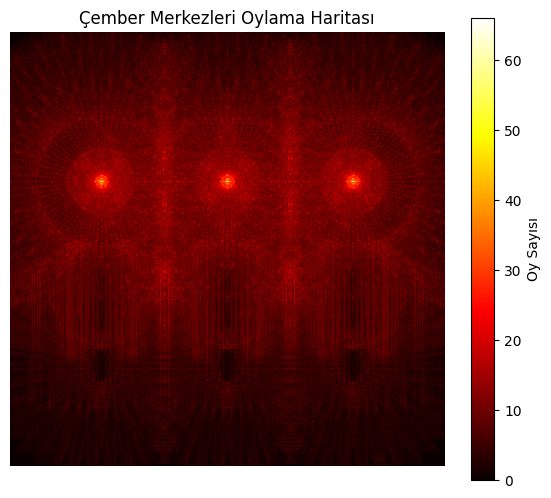

In [11]:
oylama_gorsel = np.max(oylama, axis=0)

plt.figure(figsize=(7, 6))
plt.imshow(oylama_gorsel, cmap="hot")
plt.title("Çember Merkezleri Oylama Haritası")
plt.colorbar(label="Oy Sayısı")
plt.axis("off")

plt.savefig("cember_oylama_haritasi.png", dpi=200)
plt.show()

np.save("oylama_3d.npy", oylama)


In [12]:
esik = max(18, int(oylama.max() * 0.55))

adaylar = np.argwhere(oylama >= esik)

oylar = oylama[
    adaylar[:, 0],
    adaylar[:, 1],
    adaylar[:, 2]
]

sirali = np.argsort(oylar)[::-1]

cemberler = []

for i in sirali:

    r_indeks, y, x = adaylar[i]

    r = int(yaricaplar[r_indeks])
    x = int(x)
    y = int(y)

    tekrar = False

    for cx, cy, cr in cemberler:
        uzaklik = np.hypot(x - cx, y - cy)

        if uzaklik < max(12, 0.8 * min(r, cr)):
            tekrar = True
            break

    if not tekrar:
        cemberler.append((x, y, r))

    if len(cemberler) >= 5:
        break

print("Eşik değeri:", esik)
print("Bulunan çember sayısı:", len(cemberler))
print("Çemberler:", cemberler)

Eşik değeri: 36
Bulunan çember sayısı: 3
Çemberler: [(75, 124, 36), (284, 124, 36), (179, 124, 36)]


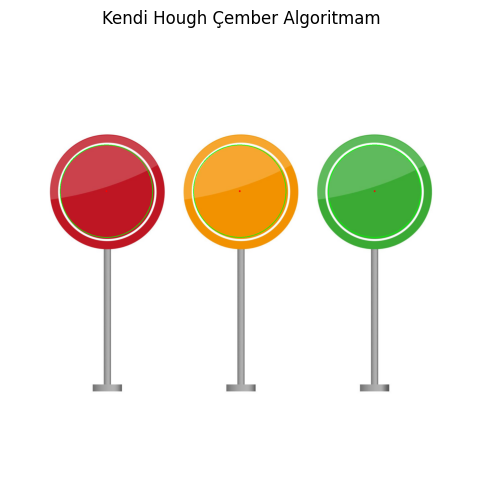

True

In [14]:
sonuc = orijinal.copy()

oran_x = orijinal.shape[1] / genislik
oran_y = orijinal.shape[0] / yukseklik

for x, y, r in cemberler:

    cx = int(round(x * oran_x))
    cy = int(round(y * oran_y))
    cr = int(round(r * (oran_x + oran_y) / 2))
#çemberi yeşil çiz
    cv2.circle(
        sonuc, (cx, cy), cr,
        (0, 255, 0), 2
    )
#merkezi kırmızı çiz
    cv2.circle(
        sonuc, (cx, cy), 4,
        (0, 0, 255), -1
    )

plt.figure(figsize=(9, 6))
plt.imshow(cv2.cvtColor(sonuc, cv2.COLOR_BGR2RGB))
plt.title("Kendi Hough Çember Algoritmam")
plt.axis("off")
plt.show()

cv2.imwrite("odev4_sonuc.png", sonuc)

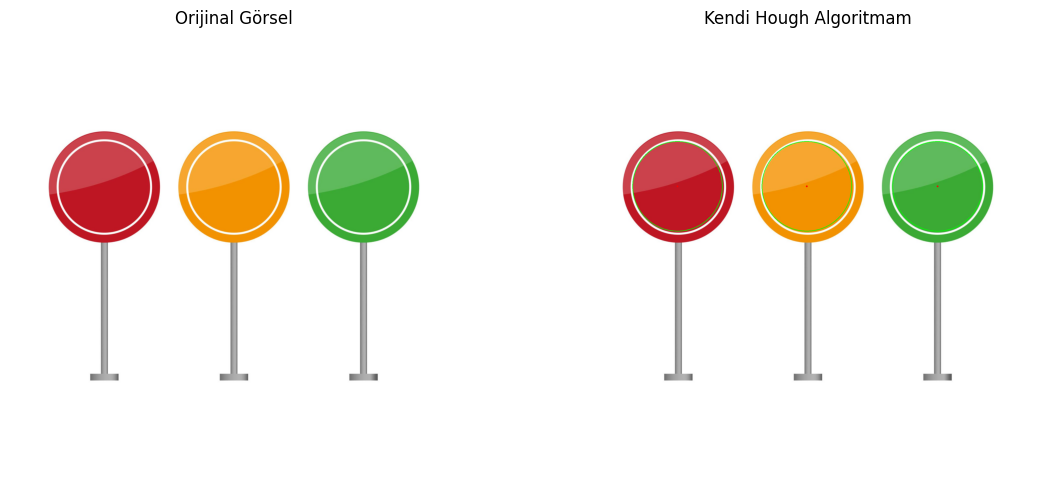

In [15]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(orijinal, cv2.COLOR_BGR2RGB))
plt.title("Orijinal Görsel")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(sonuc, cv2.COLOR_BGR2RGB))
plt.title("Kendi Hough Algoritmam")
plt.axis("off")

plt.tight_layout()
plt.savefig("odev4_karsilastirma.png", dpi=200)
plt.show()